# d × k 实验：串行题 × 约束条数（DA / CoT）

## 目标

在 **task A 的串行指针题**（`current = next[current]`，40 行编号表）上跑完整的 `d × k` 网格：

- `d = 1..10`（串行深度）
- `k = 1..5`（输出约束条数）
- 每格 **40 题**，同一 `d` 下的 `k=1..5` **共用同一批 40 题**
- 两种模式：`DA` / `CoT`，只由 system prompt 决定（模型是非 thinking 版，不传 `enable_thinking`）

核心读出量：**每个格子的联合正确率**（答案对 **且** 所有约束都满足），以及
**热力图 = 每格的 `joint(DA) − joint(CoT)`**。

## 约束怎么放（按你的规定）

| k | 放进 system prompt 的约束 |
|---|---|
| 1 | 只有输出格式（`####ANSWER=<整数>` 必须在最后一行） |
| 2 | 再加 1 条 **C1–C6 里随机抽**的常量行 |
| 3 | 再把**这道题能激活的那一条条件式**加进来（`next_start` 落在它的区间） |
| 4 | 再加 1 条随机约束 |
| 5 | 再加 1 条随机约束 |

**嵌套**：`k=2 ⊂ k=3 ⊂ k=4 ⊂ k=5`，同一道题从 k=2 到 k=5 只是「逐条加」，不换题、不换已有约束。
随机的部分用 `random.Random(SEED|qid)` 固定，重跑可复现。

**k≥4 的随机池**：剩下的 C1–C6 + **未激活的条件式**（它们要求「不要写那一行」，是一种否定约束）。

## 题目筛选

- 只用 `kind == "serial"`、`d ∈ 1..10` 的题。
- 只用 `next_start ∈ 0..35` 的题（36–39 没有任何条件式会激活，k≥3 时会缺一条约束）。
- 每个 `d` 从符合条件的一百来题里按固定种子抽 **40 题**，`k=1..5` 共用。

`next_start` 的定义：`table[initial].value`，等价于 `chains[0].trace[0]`（已在 20 条题上核对过）。

## 产物

| 文件 | 内容 |
|---|---|
| `d_x_k_io.jsonl` | 每条生成一行：`system` / `user` / `output` + 判分 |
| `d_x_k_metrics.json` | 每格汇总、每格违反明细、gap 矩阵、逐题结果 |
| `d_x_k_heatmap.png` | `d × k` 的联合正确率 gap 热力图 |

## 判分口径

- `answer_ok`：`####ANSWER=` 后面的整数 == 标准答案。
- `cons_ok`：格式合法（恰好一个答案行且有整数）+ 答案行是最后一行 + **每条约束都满足**。
- `joint_ok` = `answer_ok and cons_ok`。
- **不惩罚草稿**：多写的推理行（只要在答案行之前）不算违反约束，只记 `n_lines` 作诊断。
- 违反明细记录到「哪一条约束没满足」，包括格式本身（记为 `BASE`）。


In [1]:
import sys, os, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle")

if IN_COLAB or IN_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vllm", "pandas", "matplotlib"], check=True)
    print("vLLM 安装完成。若提示 restart，请重启会话后从下一格开始。")
else:
    print("非 Colab/Kaggle 环境，跳过安装（本机已装 vLLM 时不需要这一格）。")


# ---- torchaudio / torch 的 CUDA 版本不匹配会导致 from vllm import 直接失败 ----
# 本项目是纯文本任务，用不到 torchaudio；import 失败就卸掉。
# def drop_broken_torchaudio(verbose=True):
#     if importlib.util.find_spec("torchaudio") is None:
#         return False
#     r = subprocess.run([sys.executable, "-c", "import torchaudio"], capture_output=True, text=True)
#     if r.returncode == 0:
#         return False
#     if verbose:
#         tail = (r.stderr or "").strip().splitlines()[-1:] or ["(no stderr)"]
#         print("[fix] torchaudio 导入失败：%s" % tail[0])
#     subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchaudio"], check=False)
#     return True


# if drop_broken_torchaudio():
#     print("[fix] 已卸载 torchaudio。若随后 import vllm 仍报同样的错，请重启内核再从头跑。")


非 Colab/Kaggle 环境，跳过安装（本机已装 vLLM 时不需要这一格）。


## 2. 配置

- 路径从当前目录往上找 `Experiments/`，在仓库任意子目录启动都能跑。
- `DTYPE = "bfloat16"`：4090 支持 bf16，用全精度；**如果换回 T4 必须改成 `"float16"`**（Turing 不支持 bf16）。
- `SMOKE=True` 只跑 `d=1,2 × k=1..5 × 5 题`，用来验证链路。


In [2]:
import json, os, re, sys, time, random, math
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd

# ---------- 路径 ----------
def find_repo():
    here = Path.cwd()
    for p in [here] + list(here.parents):
        if (p / "Experiments" / "data_generation" / "synthesis_pointer_numeric_dataset.jsonl").exists():
            return p
    return here


REPO = find_repo()
DATA_DIR = REPO / "Experiments" / "data_generation"
OUT_DIR = REPO / "Experiments" / "final_experiments"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET = DATA_DIR / "synthesis_pointer_numeric_dataset.jsonl"
CONSTRAINS = OUT_DIR / "constrains.jsonl"

# ---------- 实验网格 ----------
D_GRID = list(range(1, 11))
K_GRID = list(range(1, 6))
N_PER_CELL = 40
SEED = 20261110
MODES = ("DA", "CoT")

# ---------- 模型 ----------
HF_ID = "Qwen/Qwen3-4B-Instruct-2507"
DTYPE = "bfloat16"          # 4090；T4 请改 "float16"
GPU_UTIL = 0.90
MAX_MODEL_LEN = 8192
MAX_NUM_SEQS = 32
TEMPERATURE, TOP_P = 0.6, 0.95
MAX_TOKENS = {"DA": 256, "CoT": 2048}

# ---------- 阶段 ----------
SMOKE = False               # True 时只跑 d=1,2 × 5 题
SMOKE_D = (1, 2)
SMOKE_N = 5
STAGE = "smoke" if SMOKE else "full"

# ---------- 产物 ----------
OUT_IO = OUT_DIR / ("d_x_k_io.jsonl")
OUT_METRICS = OUT_DIR / "d_x_k_metrics.json"
OUT_HEATMAP = OUT_DIR / "d_x_k_heatmap.png"

print("REPO:", REPO)
print("DATASET:", DATASET, DATASET.exists())
print("CONSTRAINS:", CONSTRAINS, CONSTRAINS.exists())
print("grid: d=%s, k=%s, %d questions/cell, modes=%s" % (D_GRID, K_GRID, N_PER_CELL, MODES))
print("stage:", STAGE, "| dtype:", DTYPE)
print("io:", OUT_IO)


REPO: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project
DATASET: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/data_generation/synthesis_pointer_numeric_dataset.jsonl True
CONSTRAINS: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/final_experiments/constrains.jsonl True
grid: d=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10], k=[1, 2, 3, 4, 5], 40 questions/cell, modes=('DA', 'CoT')
stage: full | dtype: bfloat16
io: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/final_experiments/d_x_k_io.jsonl


## 3. 读题 + 抽样

只保留 `kind == "serial"`、`d ∈ 1..10`、`next_start ∈ 0..35` 的题。
每个 `d` 用固定种子抽 40 题，`k=1..5` 共用这一批。

`next_start` 直接由 `table[initial].value` 算，并和 `chains[0].trace[0]` 对一遍，防止字段理解错。


In [3]:
serial_all = defaultdict(list)
checked = 0
with open(DATASET, encoding="utf-8") as f:
    for line in f:
        r = json.loads(line)
        if r["kind"] != "serial" or r["d"] not in D_GRID:
            continue
        init = r["chains"][0]["initial"]
        nxt = next(row["value"] for row in r["table"] if row["index"] == init)
        if checked < 20:
            assert nxt == r["chains"][0]["trace"][0], (r["qid"], nxt, r["chains"][0]["trace"])
            checked += 1
        if not (0 <= nxt <= 35):
            continue        # 36-39 没有条件式会激活，k>=3 会缺一条
        serial_all[r["d"]].append({
            "qid": r["qid"],
            "d": r["d"],
            "q": r["q"],
            "gold": int(r["ans"]),
            "start": int(init),
            "next_start": int(nxt),
            "table_size": r["lookup"]["TABLE_SIZE"],
            "ops": r["lookup"]["OPS"][0],
        })

QUESTIONS = []
for d in D_GRID:
    pool = serial_all[d]
    rng = random.Random("%s|d=%d" % (SEED, d))
    picked = rng.sample(pool, min(N_PER_CELL, len(pool)))
    picked.sort(key=lambda x: x["qid"])
    QUESTIONS.extend(picked)
    print("d=%2d: 可用 %3d 题 -> 抽 %2d 题" % (d, len(pool), len(picked)))

assert len(QUESTIONS) == N_PER_CELL * len(D_GRID), len(QUESTIONS)
df_q = pd.DataFrame(QUESTIONS)
print("\nnext_start 范围:", int(df_q["next_start"].min()), "-", int(df_q["next_start"].max()))
print("gold 范围:", int(df_q["gold"].min()), "-", int(df_q["gold"].max()))
display(df_q.head(3)[["qid", "d", "start", "next_start", "gold"]])


d= 1: 可用  91 题 -> 抽 40 题
d= 2: 可用  91 题 -> 抽 40 题
d= 3: 可用  90 题 -> 抽 40 题
d= 4: 可用  93 题 -> 抽 40 题
d= 5: 可用  93 题 -> 抽 40 题
d= 6: 可用  88 题 -> 抽 40 题
d= 7: 可用  89 题 -> 抽 40 题
d= 8: 可用  87 题 -> 抽 40 题
d= 9: 可用  92 题 -> 抽 40 题
d=10: 可用  92 题 -> 抽 40 题

next_start 范围: 0 - 35
gold 范围: 0 - 39


,qid,d,start,next_start,gold
0,099091ff62f52bde77408f12469d43734a4744f1f661fc...,1,32,27,27
1,0d223e1c7ea92cd2bffca591af6f44c771facd049913b3...,1,30,23,23
2,138a5805603b546831aa15e73b5aff25add68f7d5ccef9...,1,22,35,35


## 4. 约束

从 `constrains.jsonl` 读 12 条：6 条条件式（`cls=cond`，依赖 `next_start`）+ 6 条常量（`cls=free`）。

- 常量：要求的行**必须恰好出现一次**。
- 条件式：要求的行「出现一次」当且仅当 `next_start ∈ 区间`；不在区间时写了也算违反。

k≥4 的随机池里，未激活的条件式按同一条规则判——它要求「不要写那一行」。


In [4]:
CONS = {}
with open(CONSTRAINS, encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue
        r = json.loads(line)
        CONS[r["id"]] = r

C_IDS = [k for k, v in CONS.items() if v["cls"] == "free"]
COND_IDS = [k for k, v in CONS.items() if v["cls"] == "cond"]
assert len(C_IDS) == 6 and len(COND_IDS) == 6, (C_IDS, COND_IDS)

LITERALS = {k: v["line"] for k, v in CONS.items()}


def line_count(text, literal):
    return sum(1 for ln in str(text).splitlines() if ln.strip() == literal)


def cond_active(cid, next_start):
    return int(next_start) in CONS[cid]["condition"]["values"]


def check_cons(cid, text, next_start):
    """返回这一条约束是否满足。"""
    n = line_count(text, LITERALS[cid])
    if CONS[cid]["cls"] == "free":
        return n == 1
    return (n == 1) == cond_active(cid, next_start)


def active_cond(next_start):
    hits = [c for c in COND_IDS if cond_active(c, next_start)]
    assert len(hits) == 1, (next_start, hits)
    return hits[0]


print("free:", C_IDS)
print("cond:", [(c, CONS[c]["condition"]["values"][0], CONS[c]["condition"]["values"][-1]) for c in COND_IDS])
print("\n示例规则全文（COND_0_5）:\n" + CONS["COND_0_5"]["rule"])


free: ['C1', 'C2', 'C3', 'C4', 'C5', 'C6']
cond: [('COND_0_5', 0, 5), ('COND_6_11', 6, 11), ('COND_12_17', 12, 17), ('COND_18_23', 18, 23), ('COND_24_29', 24, 29), ('COND_30_35', 30, 35)]

示例规则全文（COND_0_5）:
If the next value of the starting index is one of 0, 1, 2, 3, 4, 5, your response must contain the line U1=N4, written exactly as shown. If the next value of the starting index is anything else, do not write that line. This conditional line must appear before the ####ANSWER= line.


## 5. 约束分配（同一题内嵌套）

```
rng = random.Random(SEED|qid)      # 每题一个，和 k 无关
k=1: []
k=2: [c2]                          # c2 从 C1-C6 抽
k=3: [c2, active]                  # active = 该题 next_start 激活的条件式
k=4: [c2, active, e1]              # e1 从「剩余 C + 未激活条件式」抽
k=5: [c2, active, e1, e2]
```

因此 `k` 是纯粹的「加一条」，同一题、同一批已有约束，只有新加的那条不同。
规则在 prompt 里的顺序就是列表顺序（`R2, R3, ...`）。


In [5]:
def plan_constraints(q):
    """同一道题，k=1..5 的约束列表（嵌套）。"""
    rng = random.Random("%s|%s" % (SEED, q["qid"]))
    c2 = rng.choice(C_IDS)
    active = active_cond(q["next_start"])
    rest = [c for c in (C_IDS + COND_IDS) if c not in (c2, active)]
    rng.shuffle(rest)
    return {
        1: [],
        2: [c2],
        3: [c2, active],
        4: [c2, active] + rest[:1],
        5: [c2, active] + rest[:2],
    }


PLANS = {q["qid"]: plan_constraints(q) for q in QUESTIONS}

# 自检：嵌套、无重复、k=3 的第三条一定是该题激活的那条
for q in QUESTIONS:
    p = PLANS[q["qid"]]
    for k in range(2, 6):
        assert len(p[k]) == k - 1, (k, p[k])
        assert len(set(p[k])) == len(p[k])
        assert p[k][: len(p[k - 1])] == p[k - 1], "k 不嵌套"
    assert active_cond(q["next_start"]) in p[3]
print("约束分配自检通过 | 示例:")
for q in QUESTIONS[:2]:
    print(" ", q["qid"][:12], "next_start=%2d" % q["next_start"], PLANS[q["qid"]])
cnt = Counter()
for q in QUESTIONS:
    for k in K_GRID:
        for c in PLANS[q["qid"]][k]:
            cnt[c] += 1
print("\n各约束被分配的题次（40 题 × 5 个 k）:", dict(sorted(cnt.items())))


约束分配自检通过 | 示例:
  099091ff62f5 next_start=27 {1: [], 2: ['C5'], 3: ['C5', 'COND_24_29'], 4: ['C5', 'COND_24_29', 'C4'], 5: ['C5', 'COND_24_29', 'C4', 'COND_6_11']}
  0d223e1c7ea9 next_start=23 {1: [], 2: ['C5'], 3: ['C5', 'COND_18_23'], 4: ['C5', 'COND_18_23', 'C6'], 5: ['C5', 'COND_18_23', 'C6', 'COND_12_17']}

各约束被分配的题次（40 题 × 5 个 k）: {'C1': 427, 'C2': 331, 'C3': 392, 'C4': 344, 'C5': 371, 'C6': 368, 'COND_0_5': 293, 'COND_12_17': 292, 'COND_18_23': 326, 'COND_24_29': 306, 'COND_30_35': 246, 'COND_6_11': 304}


## 6. Prompt 拼装

`prompts.md` 里的骨架是给「单字母答案」写的（`as one letter`）。这个任务的答案是**整数**，
所以把答案行改成 `####ANSWER= followed by the final index as an integer`，CoT 里「entry」也改成「index」。
其余措辞（禁止重复规则、禁止写没要求的行、答案行必须最后）保持不变。


In [12]:
DA_PREAMBLE = ("Answer with the final answer only: no calculations, no pointer steps, no intermediate "
               "values, no explanation and no comment. Write only the lines that the rules below require, "
               "plus the final answer line. Any other text makes the response invalid.\n")

BASE_RULE = ("Output format. Write the lines required by the rules below first, in the order the rules are "
             "listed, and then write the final answer line. The answer line is always the very last line of "
             "the response: ####ANSWER= followed by the final index as an integer, and nothing may be "
             "written after it. Do not repeat or restate these rules. Do not write any keyword line that "
             "these rules do not require.")

COT_PREAMBLE = ("Solve the problem step by step. Before the final answer line, explicitly write the index "
                "reached after each pointer step, one per line. The keyword lines required by the rules "
                "below must come after those steps and before the final answer line.\n")


def preamble(mode):
    return COT_PREAMBLE if mode == "CoT" else DA_PREAMBLE


def build_system(mode, cids):
    rules = [BASE_RULE] + [CONS[c]["rule"] for c in cids]
    body = "Rules:\n" + "\n".join("R%s. %s" % (j + 1, r) for j, r in enumerate(rules))
    # if not cids and mode != "CoT":
    #     body += ("\n\nNone of the rules above requires a keyword line, so your response must be the final "
    #              "answer line and nothing else.")
    return preamble(mode) + body


def build_messages(mode, q, cids):
    return [
        {"role": "system", "content": build_system(mode, cids)},
        {"role": "user", "content": q["q"]},
    ]


def make_jobs(questions, ks, modes, stage):
    jobs = []
    for mode in modes:
        for q in questions:
            for k in ks:
                cids = PLANS[q["qid"]][k]
                jobs.append({
                    "id": "%s|%s|d%d|k%d|%s" % (stage, mode, q["d"], k, q["qid"]),
                    "stage": stage,
                    "mode": mode,
                    "d": q["d"],
                    "k": k,
                    "qid": q["qid"],
                    "gold": q["gold"],
                    "start": q["start"],
                    "next_start": q["next_start"],
                    "constraints": list(cids),
                    "messages": build_messages(mode, q, cids),
                })
    return jobs


_jobs = make_jobs(QUESTIONS[:1], K_GRID, MODES, "selftest")
assert len(_jobs) == 2 * 5
assert len({j["id"] for j in _jobs}) == len(_jobs)
print("jobs 自检通过 | 示例（DA, k=5）:\n" + "-" * 90)
print([j for j in _jobs if j["mode"] == "DA" and j["k"] == 1][0]["messages"][0]["content"])


jobs 自检通过 | 示例（DA, k=5）:
------------------------------------------------------------------------------------------
Answer with the final answer only: no calculations, no pointer steps, no intermediate values, no explanation and no comment. Write only the lines that the rules below require, plus the final answer line. Any other text makes the response invalid.
Rules:
R1. Output format. Write the lines required by the rules below first, in the order the rules are listed, and then write the final answer line. The answer line is always the very last line of the response: ####ANSWER= followed by the final index as an integer, and nothing may be written after it. Do not repeat or restate these rules. Do not write any keyword line that these rules do not require.


## 7. 加载 vLLM（Qwen3-4B-Instruct-2507，bf16）

- `Qwen3-4B-Instruct-2507` 是**非 thinking** 模型，**不要**传 `chat_template_kwargs={"enable_thinking": ...}`。
- 4090 用 `dtype="bfloat16"`；如果哪天回 T4，必须改成 `"float16"`（Turing 不支持 bf16）。
- 采样参数沿用项目统一值：`temperature=0.6`，`top_p=0.95`。


In [7]:
import torch

# 兜底：torchaudio 版本不匹配会让 from vllm import 直接失败
# import importlib.util as _ilu
# if _ilu.find_spec("torchaudio") is not None:
#     import subprocess as _sp
#     _r = _sp.run([sys.executable, "-c", "import torchaudio"], capture_output=True, text=True)
#     if _r.returncode != 0:
#         print("[fix] torchaudio 不可用，卸载后继续")
#         _sp.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchaudio"], check=False)

from vllm import LLM, SamplingParams

if not torch.cuda.is_available():
    raise RuntimeError("没有 CUDA。请在 GPU 机器上执行这一格。")

cap = torch.cuda.get_device_capability(0)
mem_gib = torch.cuda.get_device_properties(0).total_memory / 2**30
if DTYPE == "bfloat16" and cap[0] < 8:
    raise RuntimeError("这张卡不支持 bf16（capability %s），请把 DTYPE 改成 'float16'。" % (cap,))

import os
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"

model_path = '../../models/Qwen3-4B'
llm = LLM(
    model=model_path,
    dtype=DTYPE,
    gpu_memory_utilization=GPU_UTIL,
    max_model_len=MAX_MODEL_LEN,
    max_num_seqs=MAX_NUM_SEQS,
)

CHAT_KW = {
    "chat_template_kwargs":{
        "enable_thinking": False
    }
}   # 非 thinking 模型：不传 enable_thinking
SP = {m: SamplingParams(temperature=TEMPERATURE, top_p=TOP_P, max_tokens=MAX_TOKENS[m]) for m in MODES}
print("GPU: %.1f GiB, capability %s | torch %s cuda %s" % (mem_gib, cap, torch.__version__, torch.version.cuda))
print("SP:", {m: (TEMPERATURE, TOP_P, MAX_TOKENS[m]) for m in MODES})


W1111 16:26:54.853000 20721 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1111 16:26:54.853000 20721 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1111 16:26:54.854000 20721 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=20721) INFO 11-11 16:26:57 [startup.py:96] non-default args: {'dtype': 'bfloat16', 'max_model_len': 8192, 'gpu_memory_utilization': 0.9, 'max_num_seqs': 32, 'disable_log_stats': True, 'model': '../../models/Qwen3-4B'}
(MainProcess pid=20721) INFO 11-11 16:26:57 [model.py:744] Resolved architecture: Qwen3ForCausalLM
(MainProcess pid=20721) INFO 11-11 16:26:57 [model.py:2170] Using max model len 8192
(MainProcess pid=20721) INFO 11-11 16:26:57 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=20721) INFO 11-11 16:26:57 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(MainProcess pid=20721) WARNING 11-11 16:26:59 [system_utils.py:154] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshootin

W1111 16:27:00.763000 21248 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1111 16:27:00.763000 21248 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1111 16:27:00.763000 21248 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(EngineCore pid=21248) INFO 11-11 16:27:03 [core.py:139] Initializing a V1 LLM engine (v0.33.0) with config: model='../../models/Qwen3-4B', speculative_config=None, tokenizer='../../models/Qwen3-4B', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=False, dtype=torch.bfloat16, max_seq_len=8192, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, quantization_config=None, enforce_eager=False, aux_output_config=AuxOutputConfig(enable_return_routed_experts=False, max_bytes=None), kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityConfig(show

Loading safetensors checkpoint shards:   0% Completed | 0/3 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  33% Completed | 1/3 [00:23<00:46, 23.02s/it]
Loading safetensors checkpoint shards:  67% Completed | 2/3 [00:46<00:23, 23.30s/it]
Loading safetensors checkpoint shards: 100% Completed | 3/3 [00:47<00:00, 12.92s/it]
Loading safetensors checkpoint shards: 100% Completed | 3/3 [00:47<00:00, 15.70s/it]



(EngineCore pid=21248) INFO 11-11 16:27:52 [default_loader.py:506] Loading weights took 47.09 seconds
(EngineCore pid=21248) INFO 11-11 16:27:53 [model_runner.py:428] Model loading took 7.56 GiB memory and 48.921864 seconds
(EngineCore pid=21248) INFO 11-11 16:27:53 [topk_topp_sampler.py:149] Using FlashInfer for top-p & top-k sampling.
(EngineCore pid=21248) INFO 11-11 16:27:53 [torch_utils.py:281] Reducing Torch threads from 16 to 1 for serving. Set OMP_NUM_THREADS in the external environment to override.
(EngineCore pid=21248) INFO 11-11 16:27:53 [utils.py:381] Using LBNHC KV cache layout.
(EngineCore pid=21248) INFO 11-11 16:27:55 [caching.py:342] reconstructed serializable fn from standalone compile artifacts. num_artifacts=3 num_submods=37
(EngineCore pid=21248) INFO 11-11 16:27:55 [decorators.py:326] [backbone] Directly load AOT compilation from path /home/ubuntu-user/.cache/vllm/torch_compile_cache/torch_aot_compile/a84315507f0c9ea1e07d611536e06364b3b2d8b8b25b92ab9981c71502555b

Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00, 54.16it/s]


(EngineCore pid=21248) INFO 11-11 16:27:57 [model_runner.py:1163] Graph capturing finished in 1 secs, took 0.12 GiB
(EngineCore pid=21248) INFO 11-11 16:27:57 [gpu_worker.py:772] Available KV cache memory: 12.85 GiB
(EngineCore pid=21248) INFO 11-11 16:27:57 [gpu_worker.py:787] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.9000 is equivalent to --gpu-memory-utilization=0.8946 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.9054. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=21248) INFO 11-11 16:27:57 [kv_cache_utils.py:1147] GPU KV cache size: 93,552 tokens, Maximum concurrency for 8,192 tokens per request: 11.42x
(EngineCore pid=21248) INFO 11-11 16:27:57 [kernel_warmup.py:179] JIT kernel warmup starting.
(EngineCore pid=21248) INFO 11-11 16:27:57 [kernel_warmup.py:192] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 7/7 [00:00<00:00, 61.88it/s]


(EngineCore pid=21248) INFO 11-11 16:27:58 [model_runner.py:1163] Graph capturing finished in 1 secs, took 0.07 GiB
(EngineCore pid=21248) INFO 11-11 16:27:58 [gpu_worker.py:1003] CUDA graph pool memory: 0.07 GiB (actual), 0.13 GiB (estimated), difference: 0.06 GiB (85.8%).
(EngineCore pid=21248) INFO 11-11 16:27:58 [gpu_worker.py:1066] Free memory on device (22.56/23.51 GiB) on startup. Desired GPU memory utilization is (0.9, 21.16 GiB). Actual usage is 7.6 GiB for consumed memory (weights + non-torch), 0.71 GiB for peak activation, and 0.07 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=13566015488` (12.63 GiB) to fit into requested memory, or `--kv-cache-memory=15072557056` (14.04 GiB) to fully utilize gpu memory. Current kv cache memory in use is 12.85 GiB.
(EngineCore pid=21248) INFO 11-11 16:27:58 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=21248) INFO 11

## 8. 生成与判分

- 结果追加写 `d_x_k_io.jsonl`，按 `id` 断点续跑。
- 每条记录保留 `system` / `user` / `output`，以及这道题的约束列表。
- 判分：`answer_ok`、`cons_ok`、`joint_ok`、逐条 `per_cons`、`n_lines`、`trunc`。

答案行解析：`####ANSWER=` 后面必须是**一个整数**（允许前后空格）。格式不合法、出现多个答案行、
或答案行不是最后一行，都记 `BASE` 违反。


In [1]:
MARK = "####ANSWER="


def load_done(path):
    if not path.exists():
        return set()
    with open(path, encoding="utf-8") as f:
        return {json.loads(l)["id"] for l in f if l.strip()}


def run_jobs(jobs, path=OUT_IO):
    done = load_done(path)
    todo = [j for j in jobs if j["id"] not in done]
    print("总计 %s，已完成 %s，待跑 %s" % (len(jobs), len(jobs) - len(todo), len(todo)))
    for mode in MODES:
        part = [j for j in todo if j["mode"] == mode]
        batch = 64 if mode == "DA" else 32
        for s in range(0, len(part), batch):
            chunk = part[s:s + batch]
            t0 = time.time()
            outs = llm.chat([j["messages"] for j in chunk], SP[mode], use_tqdm=False, **CHAT_KW)
            dt = time.time() - t0
            with open(path, "a", encoding="utf-8") as f:
                for j, o in zip(chunk, outs):
                    c = o.outputs[0]
                    rec = dict(j)
                    rec.pop("messages", None)
                    rec.update(
                        system=j["messages"][0]["content"],
                        user=j["messages"][1]["content"],
                        output=c.text,
                        prompt_tokens=len(o.prompt_token_ids),
                        n_tokens=len(c.token_ids),
                        finish_reason=c.finish_reason,
                        trunc=(c.finish_reason == "length"),
                        batch_sec=round(dt, 2),
                    )
                    f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            print("[%s] %s/%s  batch %.1fs" % (mode, s + len(chunk), len(part), dt))


def parse_answer(text):
    """返回 (答案整数或 None, 状态说明)。"""
    lines = [l.strip() for l in str(text).splitlines() if l.strip()]
    marks = [i for i, l in enumerate(lines) if l.startswith(MARK)]
    if len(marks) == 0:
        return None, "no_marker"
    if len(marks) > 1:
        return None, "multi_marker"
    i = marks[0]
    if i != len(lines) - 1:
        return None, "not_last"
    raw = lines[i][len(MARK):].strip()
    if not re.fullmatch(r"-?\d+", raw):
        return None, "not_int"
    return int(raw), "ok"


def score_row(rec):
    text = rec["output"]
    ans, why = parse_answer(text)
    base_ok = (why == "ok")
    answer_ok = base_ok and (ans == int(rec["gold"]))

    per = {cid: check_cons(cid, text, rec["next_start"]) for cid in rec["constraints"]}
    cons_ok = base_ok and all(per.values())
    joint_ok = answer_ok and cons_ok

    lines = [l for l in str(text).splitlines() if l.strip()]
    violated = ([] if base_ok else ["BASE"]) + [c for c, ok in per.items() if not ok]
    return {
        "answer": ans,
        "answer_ok": bool(answer_ok),
        "base_ok": bool(base_ok),
        "base_reason": why,
        "cons_ok": bool(cons_ok),
        "joint_ok": bool(joint_ok),
        "per_cons": per,
        "violated": violated,
        "n_lines": len(lines),
        "n_tokens": rec["n_tokens"],
        "trunc": bool(rec["trunc"]),
    }


NameError: name 'OUT_IO' is not defined

## 9. 冒烟（可选）

`SMOKE=True` 时只跑 `d=1,2 × k=1..5 × 5 题 × 2 模式` = 100 条，用来确认
① 题干能进模型、② 答案行能解析、③ 约束检查能跑通。跑完把 `SMOKE` 改回 `False` 再跑全量。

这一格在任何情况下都可以跑，不会污染全量（`stage` 不同、id 不同）。


In [16]:
smoke_qs = [q for q in QUESTIONS if q["d"] in SMOKE_D][:SMOKE_N * len(SMOKE_D)]
smoke_jobs = make_jobs(smoke_qs, K_GRID, MODES, "smoke")
print("smoke questions:", len(smoke_qs), "| jobs:", len(smoke_jobs))
run_jobs(smoke_jobs)

sm = []
if OUT_IO.exists():
    with open(OUT_IO, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rr = json.loads(line)
                if rr["stage"] == "smoke":
                    sm.append(rr)
if sm:
    sdf = pd.DataFrame([{**r, **score_row(r)} for r in sm])
    display(sdf.groupby(["d", "k", "mode"]).agg(
        n=("qid", "size"), answer=("answer_ok", "mean"), cons=("cons_ok", "mean"),
        joint=("joint_ok", "mean"), trunc=("trunc", "mean"), n_lines=("n_lines", "median"),
    ).round(3))
    bad = sdf[~sdf["base_ok"]]
    if len(bad):
        print("\n格式解析失败的样本（前 3 条 base_reason）:", bad["base_reason"].value_counts().to_dict())
        for _, r in bad.head(3).iterrows():
            print("-" * 60, r["d"], r["k"], r["mode"])
            print(repr(r["output"])[:300])


smoke questions: 10 | jobs: 100
总计 100，已完成 0，待跑 100
[DA] 50/50  batch 1.6s
[CoT] 32/50  batch 23.0s
[CoT] 50/50  batch 21.2s


n  answer  cons  joint  trunc  n_lines
d k mode                                         
1 1 CoT   10     0.0   0.9    0.0    0.1      3.0
    DA    10     0.3   1.0    0.3    0.0      1.0
  2 CoT   10     0.5   0.9    0.5    0.0     42.0
    DA    10     0.4   1.0    0.4    0.0      2.0
  3 CoT   10     0.5   0.7    0.4    0.1     43.0
    DA    10     0.3   1.0    0.3    0.0      3.0
  4 CoT   10     0.7   0.9    0.6    0.0     43.0
    DA    10     0.1   0.7    0.1    0.0      4.0
  5 CoT   10     0.7   0.4    0.3    0.1     27.0
    DA    10     0.2   0.6    0.1    0.0      4.0


格式解析失败的样本（前 3 条 base_reason）: {'no_marker': 3, 'not_last': 1}
------------------------------------------------------------ 1 2 CoT
'current = 32\nindex reached after each pointer step:\n32\n####ANSWER=33\nT5=W5'
------------------------------------------------------------ 1 5 CoT
'0 | 14\n1 | 31\n2 | 10\n3 | 14\n4 | 12\n5 | 12\n6 | 39\n7 | 28\n8 | 22\n9 | 11\n10 | 8\n11 | 24\n12 | 24\n13 | 7\n14 | 6\n15 | 11\n16 | 0\n17 | 25\n18 | 21\n19 | 38\n20 | 33\n21 | 33\n22 | 26\n23 | 9\n24 | 31\n25 | 5\n26 | 7\n27 | 8\n28 | 27\n29 | 34\n30 | 23\n31 | 21\n32 | 25\n33 | 36\n34 | 16\n35
------------------------------------------------------------ 1 3 CoT
'Current = 22\nIndex reached: 22\nNext value: 35\nIndex reached: 35\nNext value: 6\nIndex reached: 6\nNext value: 37\nIndex reached: 37\nNext value: 5\nIndex reached: 5\nNext value: 33\nIndex reached: 33\nNext value: 37\nIndex reached: 37\nNext value: 5\nIndex reached: 5\nNext value: 33\nIndex reach


## 10. 全量运行

`d=1..10` × `k=1..5` × 40 题 × 2 模式 = **4000 条**。
可中断；重跑本格会按 `id` 跳过已完成的。

预计 4090 上 20–40 分钟（题干带 40 行表，prefill 占大头）。


In [11]:
jobs = make_jobs(QUESTIONS, K_GRID, MODES, "full")
print("jobs:", len(jobs))
run_jobs(jobs)

rows = [json.loads(l) for l in open(OUT_IO, encoding="utf-8") if l.strip()]
rows = [r for r in rows if r["stage"] == "full"]
print("full 已完成:", len(rows))
assert len(rows) == len(jobs), "还没跑完，重跑本格续跑"


jobs: 4000
总计 4000，已完成 0，待跑 4000
[DA] 64/2000  batch 2.0s
[DA] 128/2000  batch 2.0s
[DA] 192/2000  batch 2.1s
[DA] 256/2000  batch 2.9s
[DA] 320/2000  batch 2.1s
[DA] 384/2000  batch 2.7s
[DA] 448/2000  batch 2.7s
[DA] 512/2000  batch 2.1s
[DA] 576/2000  batch 3.1s
[DA] 640/2000  batch 2.9s
[DA] 704/2000  batch 2.3s
[DA] 768/2000  batch 2.3s
[DA] 832/2000  batch 3.2s
[DA] 896/2000  batch 2.5s
[DA] 960/2000  batch 2.4s
[DA] 1024/2000  batch 2.4s
[DA] 1088/2000  batch 2.5s
[DA] 1152/2000  batch 3.4s
[DA] 1216/2000  batch 2.5s
[DA] 1280/2000  batch 2.6s
[DA] 1344/2000  batch 2.6s
[DA] 1408/2000  batch 2.6s
[DA] 1472/2000  batch 2.7s
[DA] 1536/2000  batch 2.6s
[DA] 1600/2000  batch 2.7s
[DA] 1664/2000  batch 2.6s
[DA] 1728/2000  batch 2.7s
[DA] 1792/2000  batch 2.7s
[DA] 1856/2000  batch 2.7s
[DA] 1920/2000  batch 2.7s
[DA] 1984/2000  batch 2.7s
[DA] 2000/2000  batch 0.9s
[CoT] 32/2000  batch 22.2s
[CoT] 64/2000  batch 24.3s
[CoT] 96/2000  batch 22.7s
[CoT] 128/2000  batch 22.7s
[CoT] 160/

## 11. 汇总、metrics.json 与热力图

- **每格**（d, k, mode）：`answer_rate` / `cons_rate` / `joint_rate`，以及每格各约束的违反次数。
- **gap 矩阵**：`joint(DA) − joint(CoT)`，就是热力图的取值。
- 逐题结果也写进同一个 `metrics.json`，方便回查「这道题为什么没通过」。

热力图：行 = d（1..10），列 = k（1..5），色标居中于 0（蓝 = CoT 更好，红 = DA 更好）。


k         1             2             3             4             5       
mode    CoT     DA    CoT     DA    CoT     DA    CoT     DA    CoT     DA
d                                                                         
1     0.175  0.475  0.550  0.575  0.700  0.400  0.575  0.275  0.300  0.250
2     0.425  0.075  0.225  0.075  0.325  0.025  0.225  0.000  0.075  0.025
3     0.475  0.025  0.275  0.050  0.375  0.000  0.250  0.000  0.050  0.000
4     0.575  0.000  0.275  0.000  0.200  0.025  0.200  0.000  0.075  0.000
5     0.575  0.025  0.175  0.025  0.375  0.000  0.100  0.025  0.100  0.000
6     0.650  0.000  0.125  0.025  0.125  0.000  0.000  0.000  0.025  0.025
7     0.525  0.000  0.125  0.000  0.150  0.050  0.100  0.000  0.100  0.000
8     0.575  0.050  0.225  0.025  0.200  0.000  0.075  0.000  0.050  0.025
9     0.625  0.025  0.300  0.000  0.050  0.000  0.025  0.000  0.000  0.000
10    0.475  0.050  0.125  0.000  0.250  0.025  0.100  0.000  0.050  0.000


联合正确率 gap（DA - CoT）:


k,1,2,3,4,5
d,,,,,
1,0.300,0.025,-0.300,-0.300,-0.050
2,-0.350,-0.150,-0.300,-0.225,-0.050
3,-0.450,-0.225,-0.375,-0.250,-0.050
4,-0.575,-0.275,-0.175,-0.200,-0.075
5,-0.550,-0.150,-0.375,-0.075,-0.100
6,-0.650,-0.100,-0.125,0.000,0.000
7,-0.525,-0.125,-0.100,-0.100,-0.100
8,-0.525,-0.200,-0.200,-0.075,-0.025
9,-0.600,-0.300,-0.050,-0.025,0.000



written: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/final_experiments/d_x_k_metrics.json | rows: 4000


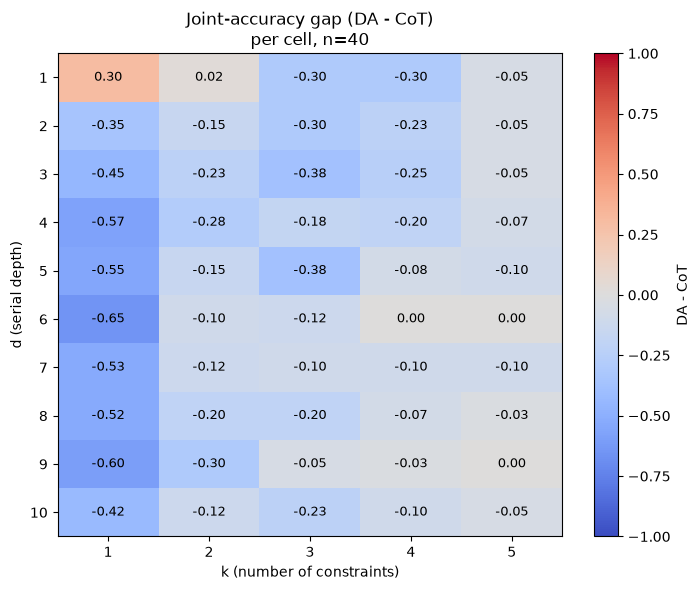

written: /home/ubuntu-user/Desktop/Sandoleathy/CISC7404-Project/Experiments/final_experiments/d_x_k_heatmap.png


In [12]:
try:
    import matplotlib
    import matplotlib.pyplot as plt
    HAVE_MPL = True
except Exception as e:
    HAVE_MPL = False
    print("[warn] matplotlib 不可用，热力图会退化成 csv:", e)

rows = [json.loads(l) for l in open(OUT_IO, encoding="utf-8") if l.strip()]
rows = [r for r in rows if r["stage"] == "full"]
scored = []
for r in rows:
    s = score_row(r)
    rec = {k: r[k] for k in ("id", "stage", "mode", "d", "k", "qid", "gold", "start", "next_start",
                             "constraints", "finish_reason", "prompt_tokens")}
    rec.update(s)
    rec["output"] = r["output"]
    scored.append(rec)

df = pd.DataFrame(scored)

# ---- 每格汇总 ----
cells = []
for (d, k, mode), g in df.groupby(["d", "k", "mode"]):
    viol = Counter()
    for v in g["violated"]:
        for c in v:
            viol[c] += 1
    cells.append({
        "d": int(d), "k": int(k), "mode": mode, "n": int(len(g)),
        "answer_rate": float(g["answer_ok"].mean()),
        "cons_rate": float(g["cons_ok"].mean()),
        "joint_rate": float(g["joint_ok"].mean()),
        "trunc_rate": float(g["trunc"].mean()),
        "n_lines_median": float(g["n_lines"].median()),
        "violations": dict(sorted(viol.items())),
    })
cell_df = pd.DataFrame(cells)
display(cell_df.pivot_table(index="d", columns=["k", "mode"], values="joint_rate").round(3))

# ---- gap 矩阵 ----
j = df.pivot_table(index=["d", "k"], columns="mode", values="joint_ok", aggfunc="mean").reset_index()
j["gap"] = j["DA"] - j["CoT"]
gap_mat = j.pivot(index="d", columns="k", values="gap").reindex(index=D_GRID, columns=K_GRID)
joint_da = j.pivot(index="d", columns="k", values="DA").reindex(index=D_GRID, columns=K_GRID)
joint_cot = j.pivot(index="d", columns="k", values="CoT").reindex(index=D_GRID, columns=K_GRID)
print("\n联合正确率 gap（DA - CoT）:")
display(gap_mat.round(3))

# ---- 写 metrics.json ----
metrics = {
    "meta": {
        "model": HF_ID,
        "dtype": DTYPE,
        "dataset": str(DATASET.relative_to(REPO)),
        "constrains": str(CONSTRAINS.relative_to(REPO)),
        "stage": "full",
        "d_grid": D_GRID,
        "k_grid": K_GRID,
        "n_per_cell": N_PER_CELL,
        "seed": SEED,
        "modes": list(MODES),
        "temperature": TEMPERATURE,
        "top_p": TOP_P,
        "max_tokens": MAX_TOKENS,
        "n_rows": int(len(df)),
        "judge": {
            "answer": "####ANSWER=<int> on the last line",
            "cons": "base format + every constraint (nesting k=2..5)",
            "joint": "answer_ok and cons_ok",
            "scratch": "not penalized (only lines after the answer matter)",
        },
    },
    "cells": cells,
    "gap": [
        {"d": int(d), "k": int(k),
         "joint_da": float(joint_da.loc[d, k]), "joint_cot": float(joint_cot.loc[d, k]),
         "gap": float(gap_mat.loc[d, k])}
        for d in D_GRID for k in K_GRID
    ],
    "questions": [
        {k: (bool(v) if isinstance(v, (bool, np.bool_)) else (int(v) if isinstance(v, (int, np.integer)) else v))
         for k, v in rec.items()}
        for rec in scored
    ],
}
with open(OUT_METRICS, "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("\nwritten:", OUT_METRICS, "| rows:", len(df))

# ---- 热力图 ----
if HAVE_MPL:
    try:
        fig, ax = plt.subplots(figsize=(7.2, 6.0))
        im = ax.imshow(gap_mat.values.astype(float), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
        ax.set_xticks(range(len(K_GRID)))
        ax.set_xticklabels(K_GRID)
        ax.set_yticks(range(len(D_GRID)))
        ax.set_yticklabels(D_GRID)
        ax.set_xlabel("k (number of constraints)")
        ax.set_ylabel("d (serial depth)")
        ax.set_title("Joint-accuracy gap (DA - CoT)\nper cell, n=%d" % N_PER_CELL)
        for i in range(len(D_GRID)):
            for jj in range(len(K_GRID)):
                v = gap_mat.values[i, jj]
                if np.isfinite(v):
                    ax.text(jj, i, "%.2f" % v, ha="center", va="center", color="black", fontsize=9)
        fig.colorbar(im, ax=ax, label="DA - CoT")
        fig.tight_layout()
        fig.savefig(OUT_HEATMAP, dpi=150)
        plt.show()
        print("written:", OUT_HEATMAP)
    except Exception as e:
        print("[warn] 画图失败，退化成 csv:", e)
        gap_mat.to_csv(OUT_DIR / "d_x_k_gap_matrix.csv", encoding="utf-8")
        print("written:", OUT_DIR / "d_x_k_gap_matrix.csv")
else:
    gap_mat.to_csv(OUT_DIR / "d_x_k_gap_matrix.csv", encoding="utf-8")
    print("written:", OUT_DIR / "d_x_k_gap_matrix.csv")


## 12. 人工审查（必做）

- 抽 2–3 个格子看原文：`k=1` 时 DA 是不是只写答案；`k=3` 时条件式那一条有没有按题激活。
- 看 `violations`：哪条约束掉得最多？`BASE` 违反多说明答案行格式没稳住。
- 看 gap 的正负：如果大多为负（CoT 更好），说明约束在 DA 下更贵。
- 检查截断率：CoT 有没有被 2048 截断。


In [12]:
for (d, k) in [(1, 3), (5, 5), (10, 5)]:
    for mode in MODES:
        sub = df[(df["d"] == d) & (df["k"] == k) & (df["mode"] == mode)]
        if not len(sub):
            continue
        print("=" * 100)
        print("d=%d k=%d %s | joint=%.2f cons=%.2f answer=%.2f | constraints=%s" % (
            d, k, mode, sub["joint_ok"].mean(), sub["cons_ok"].mean(), sub["answer_ok"].mean(),
            sub.iloc[0]["constraints"]))
        for _, r in sub.sample(min(2, len(sub)), random_state=SEED).iterrows():
            print("-" * 70, "| violated:", r["violated"])
            print(r["output"][:800])


d=1 k=3 DA | joint=0.10 cons=0.17 answer=0.57 | constraints=['C5', 'COND_24_29']
---------------------------------------------------------------------- | violated: ['COND_30_35']
T3=M9
####ANSWER=31
---------------------------------------------------------------------- | violated: []
T4=Z2
U1=N4
####ANSWER=15
d=1 k=3 CoT | joint=0.33 cons=0.33 answer=0.85 | constraints=['C5', 'COND_24_29']
---------------------------------------------------------------------- | violated: ['COND_30_35']
0 → 31  
index reached after each pointer step: 31  

T3=M9  
####ANSWER=31
---------------------------------------------------------------------- | violated: []
0 → 5  
1 → 25  
2 → 35  
3 → 18  
4 → 20  
5 → 32  
6 → 37  
7 → 27  
8 → 19  
9 → 16  
10 → 36  
11 → 34  
12 → 36  
13 → 24  
14 → 16  
15 → 33  
16 → 28  
17 → 37  
18 → 22  
19 → 28  
20 → 13  
21 → 24  
22 → 37  
23 → 25  
24 → 21  
25 → 38  
26 → 13  
27 → 13  
28 → 18  
29 → 5  
30 → 8  
31 → 20  
32 → 36  
33 → 39  
34 → 15  
35 → 18  
